# 05 · Simulation outputs: from TNG snapshots to gas fields

`skewerjax.simulations` turns the outputs of a hydrodynamical simulation (here a TNG snapshot) into the gas along the
skewers that the optical depth needs. It is organised in layers:

| layer | module | does | arrays |
|---|---|---|---|
| 1 | `readers` | HDF5 I/O and units (`ArepoHDF5Reader`) | NumPy |
| 2 | `gas_cells` | `GasCells`: positions, volumes, physical fields | pytree |
| 3 | `gas_physics` | $n_{\rm H}$, $T$, $x_{\rm HI}$, metal ion fractions (CLOUDY) per cell | JAX |
| 4 | `selection` | the cells that can reach the skewers (periodic k-d tree, streamed) | NumPy (CPU); optional GPU back end |
| 5 | `deposition` | which cell fills which piece of every dual segment (Voronoi cells, or top-hat spheres) | NumPy (default) or JAX (`backend="jax"`) |
| 6 | `absorbers` | pieces $\to$ `core.LoSSamples` $\to$ `core.optical_depth_from_samples` | JAX |

Why the remaining NumPy steps are NumPy:

- **Reader.** The snapshot is read from HDF5 in streamed blocks (h5py); that is host I/O.
- **Selection.** It is a periodic k-d tree query (`scipy.spatial.cKDTree(boxsize=...)`) of every streamed block of cells
  against the path points.
  - Its output size, the number of selected cells, depends on the data, which static JAX shapes cannot express. It is
    pure geometry and is never differentiated.
  - `select_cells_near_paths(..., backend=...)` and `SimulationSkewers(..., selection_backend=...)` take:
    - `"cpu"` (the default);
    - `"jztree"`, a CUDA-only nearest-neighbour search with the optional package JZ-TREE, with borderline cells
      re-checked in float64 so the selected set is the same;
    - `"auto"`, which uses the GPU when that package and a CUDA device are present.
- **Deposition.** The default labels sub-points of every dual segment with the same k-d tree and merges the pieces
  with `np.unique`. `voronoi_segments(..., backend="jax")` does the same in JAX with static shapes and gives identical
  pieces. It is slower on a CPU, so it is opt-in.

`SimulationSkewers` runs the six layers for any `ExtractionOptions` and `IntegrationOptions`.

The data are TNG50-4 snapshot 25 ($z = 3.0$, 35 cMpc$/h$, 19.3 M cells), read-only. Runtime: ~1 min. The $\tau$ of these
skewers is computed in notebook 06.

**Requires:** skewers (03, with their $a(x)$ from 02) and a simulation snapshot; the atomic table (01) for the ion masses.  
**Independent of:** the toy samplers (04).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import numpy as np, jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)          # SkewerJAX follows this flag; it never sets it itself
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()      # interactive figures (ipympl) in a live notebook; inline when executed headless or without ipympl
use_style()          # paper style (white); use_style("dark") for the dark one: same colour-blind-safe palette in both
from skewerjax.utils.plotting import (ENTITY_COLORS as EC, MODE_STYLES as MS, PALETTE as TOL, FG, BG, DIM, CMAPS, LABELS,
                                      FIGSIZES, add_panel_letters, plot_dag, plot_spectra, zoom_inset)

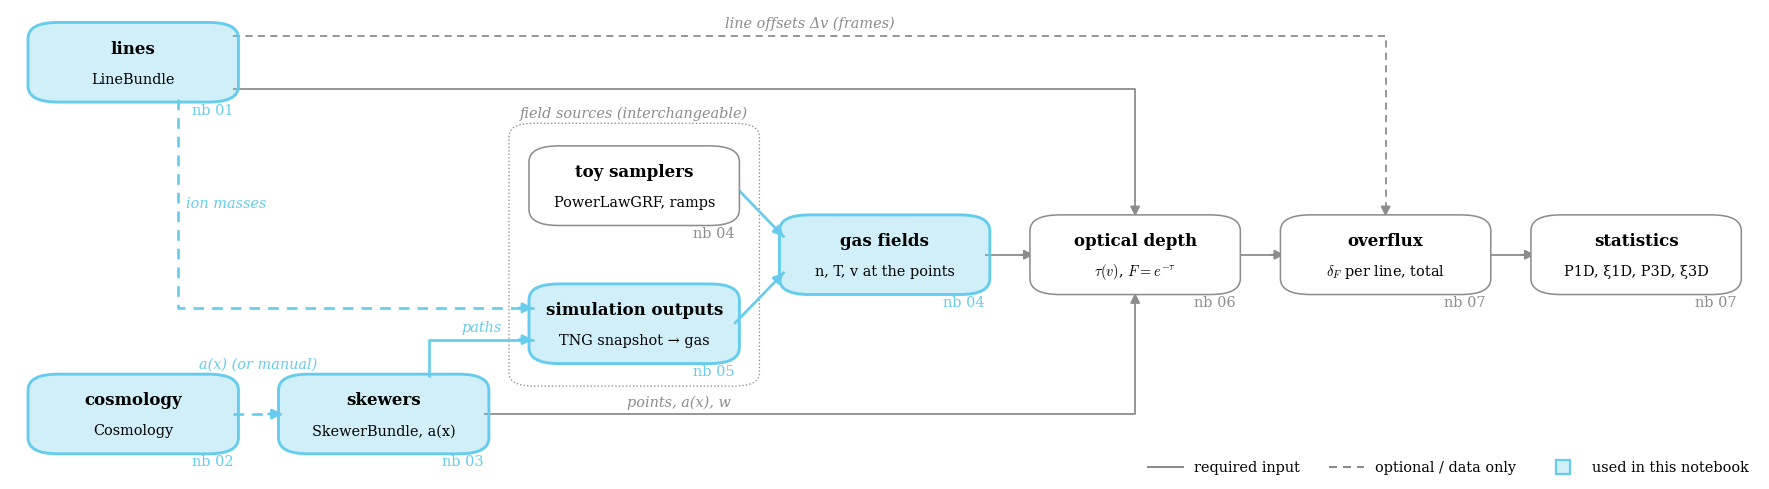

In [2]:
plot_dag(('lines', 'cosmology', 'skewers', 'simulation', 'fields',)); plt.show()

In [3]:
from skewerjax.core import LineBundle, SkewerBundle, Cosmology, phys
from skewerjax.simulations import ArepoHDF5Reader, SimulationSkewers, ExtractionOptions, IntegrationOptions, HI, Ion, gas_physics as gp
DATA = os.environ.get("SKEWERJAX_DATA", "/home/STORAGE")      # folder with TNG50-4/ (docs/installation.md)
reader = ArepoHDF5Reader(f"{DATA}/TNG50-4", 25)
H = reader.header
print(f"z = {H.redshift:.4f}, a = {H.a:.6f}, box = {H.box_cMpc:.4f} cMpc, {H.n_gas:,} gas cells in {H.n_files} files, "
      f"a H(z) L = {H.vmax_kms:.1f} km/s")

z = 3.0081, a = 0.249493, box = 51.6681 cMpc, 19,250,411 gas cells in 11 files, a H(z) L = 3961.5 km/s


## 1 · What the optical depth needs, and how the snapshot provides it

Notebook 06 derives the sum that the code evaluates from the integral along the path (review notes, Eq.
`tau_straight_los`). The result: the path is partitioned into **pieces** $p$, each a part of a dual segment $w_i$ that
lies inside one cell. Every piece contributes its own profile:

$$
\tau_j(v_\dagger) = \mathcal{C}_j \int \frac{n_{\rm com}(x)}{a(x)^{2}}\,\phi_j(v_\dagger, x)\,dx
\;\simeq\; \mathcal{C}_j \sum_p \frac{n_{{\rm com},p}\,\ell_p}{a_p^{2}}\,\phi_{j,p}(v_\dagger),
\qquad \sum_{p \in i} \ell_p = w_i,\qquad \mathcal{C}_j = \frac{e^2 f_j}{4\varepsilon_0 m_e c}.
$$

Per piece $p$ of gas on the path, the integrator therefore needs:

- the comoving density $n_{\rm com}$;
- the temperature $T$, which sets the width $b = \sqrt{2k_BT/m}$;
- the velocity along the path, $v_\parallel$, which shifts the line centre;
- the scale factor $a$ at the piece centroid, the Hubble flow from the skewer's $a(x)$;
- the length $\ell_p$.

The snapshot provides them in six steps:

| step | code | per cell or piece |
|---|---|---|
| 1. read | `readers.ArepoHDF5Reader.to_gas_cells` | positions [cMpc] = `Coordinates` $\times$ ckpc$/h$; $\rho$ [g cm$^{-3}$, physical] = `Density` $\times$ unit; $u$ [erg/g] = `InternalEnergy` $\times$ (km/s)$^2$; $v_{\rm pec}$ [km/s] = `Velocities` $\times\sqrt{a}$; $X_k$ = `GFM_Metals`; $n_e/n_{\rm H}$; SFR; stored $x_{\rm HI}$ |
| 2. cells | `gas_cells.GasCells` | $V = M/\rho$ (comoving), size $V^{1/3}$ (`size_cMpc`) |
| 3. physics | `gas_physics.ion_properties` | $n_{\rm H}$, $T$, $x_{\rm HI}$, metal ion fractions $f_{\rm ion}$ (§2); $n_{\rm ion} = \rho X_{\rm elem} f_{\rm ion}/(A\, m_u)$ |
| 4. selection | `selection.select_cells_near_paths` | the cells that can touch the paths |
| 5. deposition | `deposition.voronoi_segments` | the pieces of every dual segment: cell, exact length $\ell_p$, centroid offset (nearest mesh-generating point, i.e. Arepo's own cells) |
| 6. absorbers | `absorbers.absorbers_from_components`, `absorber_samples` | $s_p$, $n_p$, $\ell_p$, $T_p$, $v_{\parallel,p} = \mathbf{v}_{\rm pec}\cdot\hat t$; then $n_{\rm com} = n\, a_{\rm snap}^3$ and $a(s_p)$ from the frame $\to$ `core.LoSSamples` $\to$ $\tau$ |

The alternative to step 6 is `SimulationSkewers.point_values`: one value per sampling point, the segment average
$\bar n_i = \sum_{p\in i} n_p \ell_p / w_i$, with column-weighted $T$ and $v$. `fields(species)` wraps these values
as `SampledField`s (04).

## 2 · Per-cell physics (layer 3): the ingredients of the ion densities

Every ion density is

$$
n_{\rm ion} = \frac{\rho\, X_{\rm elem}}{A_{\rm elem}\, m_u}\, f_{\rm ion},
$$

with the cell's mass density $\rho$, the mass fraction $X_{\rm elem}$ of the element (`GFM_Metals`), its atomic weight
$A_{\rm elem}$ and the ion fraction $f_{\rm ion}$ (`gas_physics.ion_properties`). The ingredients:

- **Hydrogen density.** $n_{\rm H} = \rho X_{\rm H}/(A_{\rm H} m_u)$.
- **Temperature.** $T = (\gamma - 1)\,\mu\, m_p\, u/k_B$, with:
  - the internal energy $u$ and $\gamma = 5/3$;
  - the mean molecular weight $\mu = 4/(1 + 3X + 4X x_e)$, where $X = 0.76$ and $x_e = n_e/n_{\rm H}$ is the stored
    electron abundance (`gas_physics.temperature`).
- **H I fraction.** TNG stores $x_{\rm HI}$ from its own ionisation equilibrium, with the FG09 UV background, the local
  AGN radiation and the Rahmati et al. (2013) self-shielding factor.
  - SkewerJAX keeps the stored value, except in star-forming cells.
  - There it follows from the effective temperature of the two-phase medium, so those cells are recomputed at
    $T = 10^4$ K, the cold phase (`neutral_fraction`, model `"stored_sf"`).
  - The recomputation is Rahmati's photoionisation equilibrium:

$$
\frac{\Gamma_{\rm phot}}{\Gamma_{\rm UVB}} = 0.98\left[1+\left(\frac{n_{\rm H}}{n_{\rm SSh}}\right)^{1.64}\right]^{-2.28} + 0.02\left[1+\frac{n_{\rm H}}{n_{\rm SSh}}\right]^{-0.84},
\qquad
n_{\rm SSh} = 6.73\times10^{-3}\left(\frac{\sigma_\nu}{2.49\times10^{-18}}\right)^{-2/3}\left(\frac{T}{10^4}\right)^{0.17}\left(\frac{\Gamma_{\rm UVB}}{10^{-12}}\right)^{2/3}\left(\frac{f_{\rm bar}}{0.17}\right)^{-1/3}\ {\rm cm^{-3}} .
$$

  The neutral fraction $x$ then solves $\alpha_A (1 - x)^2 n_{\rm H} = x\,[\Gamma_{\rm phot} + \Gamma_{\rm coll}(1 - x)\, n_{\rm H}]$,
  with case-A recombination $\alpha_A(T)$, collisional ionisation $\Gamma_{\rm coll}(T)$ and $n_e = n_{\rm HII}$
  (`rahmati_neutral_fraction`):

$$
x = \frac{B - \sqrt{B^2 - 4 A \alpha_A}}{2A},\qquad A = \alpha_A + \Gamma_{\rm coll},\qquad B = 2\alpha_A + \frac{\Gamma_{\rm phot}}{n_{\rm H}} + \Gamma_{\rm coll} .
$$

  $\Gamma_{\rm UVB}$ is the simulation's own H I photoionisation rate (`TREECOOL_fg_dec11` at the snapshot redshift).
- **Metal ion fractions.** $f_{\rm ion} = \mathrm{CLOUDY}(n_{\rm H}, T)$ is a precomputed table of ionisation
  equilibrium: FG11 UV background, attenuated above 13.6 eV by the same self-shielding factor, and 1/10 solar
  abundances.
  - The table is interpolated linearly in redshift and bilinearly in $(\log n_{\rm H}, \log T)$ of $\log f$
    (`CloudyIonTable.fraction`).
  - CLOUDY's density coordinate is the hydrogen density, so the cell's $n_{\rm H}$ enters.

**One temperature for every species.** The same $T$ enters every ion, both in the widths, $b = \sqrt{2k_BT/(A\, m_u)}$,
and in the ion fractions.

- The hydrodynamics is single-fluid: ions, neutrals and electrons share one kinetic temperature, because collisions
  equilibrate them much faster than the gas evolves.
- What differs per species is the mass, $b_{\rm Si}/b_{\rm H} = \sqrt{1.008/28.09} = 0.19$, and the ionisation model.
- The exception is star-forming gas.
  - H I is recomputed for its cold phase ($10^4$ K), while its width and the Si III fraction still use the effective
    temperature ($1.5\times10^4$ to $2.4\times10^5$ K here).
  - A per-phase temperature would narrow these lines and change their Si III fraction; it is not done here.

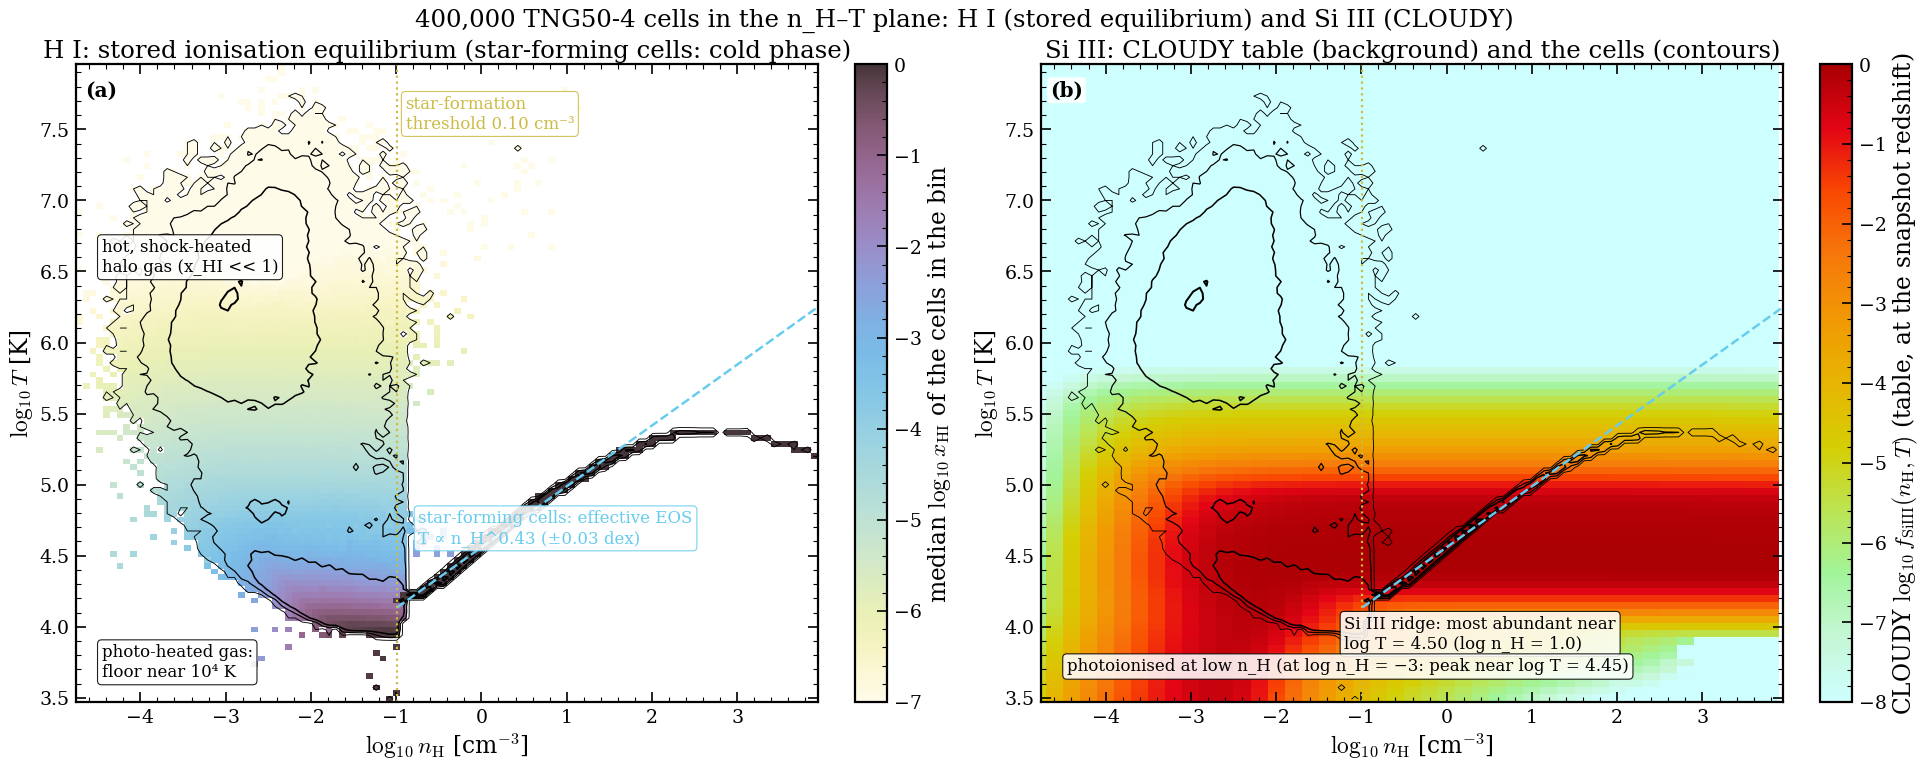

62,250 star-forming cells: n_H >= 0.102 cm^-3; log T = 0.428 log n_H + 4.56, scatter 0.031 dex
median x_HI of star-forming cells: stored 0.006, cold phase (used) 0.974; CLOUDY Si III maximum: log f = -0.04 at log T = 4.50


In [4]:
cells = reader.to_gas_cells(reader.read_rows(0, ["Coordinates", "Masses", "Density", "InternalEnergy", "ElectronAbundance",
                                                    "NeutralHydrogenAbundance", "GFM_Metals", "StarFormationRate", "Velocities"], stop=400_000))
SI3 = Ion("Si", 3)
P_HI, P_Si = gp.ion_properties(cells, HI), gp.ion_properties(cells, SI3)
sf = np.asarray(cells.fields["sfr"]) > 0
table = gp.CloudyIonTable(H.redshift)
from skewerjax.utils.plotting import plot_nH_T_fractions
n_thr = float(np.asarray(P_HI["n_H"])[sf].min())
fig, axs, info = plot_nH_T_fractions(np.asarray(P_HI["n_H"]), np.asarray(P_HI["T"]), np.asarray(P_HI["ion_fraction"]),
                                     np.asarray(P_Si["ion_fraction"]), sf, (table.log_dens, table.log_temp, table.log_fraction_grid(SI3)),
                                     n_thr=n_thr)
add_panel_letters(axs); fig.suptitle("400,000 TNG50-4 cells in the n_H–T plane: H I (stored equilibrium) and Si III (CLOUDY)", fontsize=22)
plt.show()
eos = info["eos"]
print(f"{sf.sum():,} star-forming cells: n_H >= {n_thr:.3f} cm^-3; "
      f"log T = {eos['slope']:.3f} log n_H + {eos['intercept']:.2f}, scatter {eos['scatter']:.3f} dex")
print(f"median x_HI of star-forming cells: stored {np.median(np.asarray(cells.fields['x_HI_stored'])[sf]):.3f}, "
      f"cold phase (used) {np.median(np.asarray(P_HI['ion_fraction'])[sf]):.3f}; CLOUDY Si III maximum: log f = {info['cloudy_max']['log_f']:.2f} "
      f"at log T = {info['cloudy_max']['log_T']:.2f}")

*Reading the figure.* The contours count cells (1, 10, 100 and 1000 per bin), the same in both panels.

- **The sharp cut near $n_{\rm H} \approx 10^{-1}\ \mathrm{cm^{-3}}$** is TNG's star-formation threshold (printed
  above). Above it, the gas is put on the Springel & Hernquist effective equation of state: its stored temperature is
  the pressure of a two-phase medium, a single function $T(n_{\rm H})$.
- **The thin strip to the right** is that equation of state. The star-forming cells lie on
  $\log T \approx 0.43 \log n_{\rm H} + 4.6$ with a scatter of 0.03 dex (dashed line; the fit is printed above).
- **Below the threshold**, gas cools down to the floor of photo-heated gas near $10^4$ K, the lower edge of the
  distribution. Shock-heated halo gas fills the upper part ($10^5$ to $10^7$ K), where $x_{\rm HI} \ll 1$ and almost no
  Si III survives.
- **(b)** Si III is a narrow ridge of the CLOUDY table near $10^{4.5}$ K at these densities. Collisional ionisation
  removes it above, and photoionisation at low $n_{\rm H}$. So only a small part of the cells carries Si III, mostly
  dense gas between $10^4$ and $10^5$ K.

## 3 · Selection $\to$ deposition $\to$ integration, step by step

Three different grids meet in a simulated spectrum, and the deposition is what connects them:

- **the cells:** one value per Voronoi cell, the region closer to its mesh-generating point than to any other;
- **the sampling points of the `SkewerBundle`:** point $i$ stands for its *dual segment*, between the midpoints with its
  neighbours, of length $w_i$ (the line element of 03);
- **the spectral grid** of $v$ on which $\tau$ is evaluated, chosen freely.

The steps:

1. **Selection:** the cells close enough to the path to touch it.
2. **Deposition:** which cell fills which piece of every dual segment, with its exact length $\ell_p$ and its
   centroid.
3. **Integration:** every piece adds its own profile $d\tau_p(v) = \mathcal{C}_j\, n_{{\rm com},p}\, \ell_p\, a_p^{-2}\, \phi_{j,p}(v)$,
   centred at the line centre of its centroid, $v_{c,p} = c \ln(a_\dagger/a(s_p)) + v_{\parallel,p}$, and
   $\tau = \sum_p d\tau_p$ (notebook 06 derives this sum and its accuracy).

The toy two-dimensional mesh below, with a denser filament in the middle, shows all of it at once.

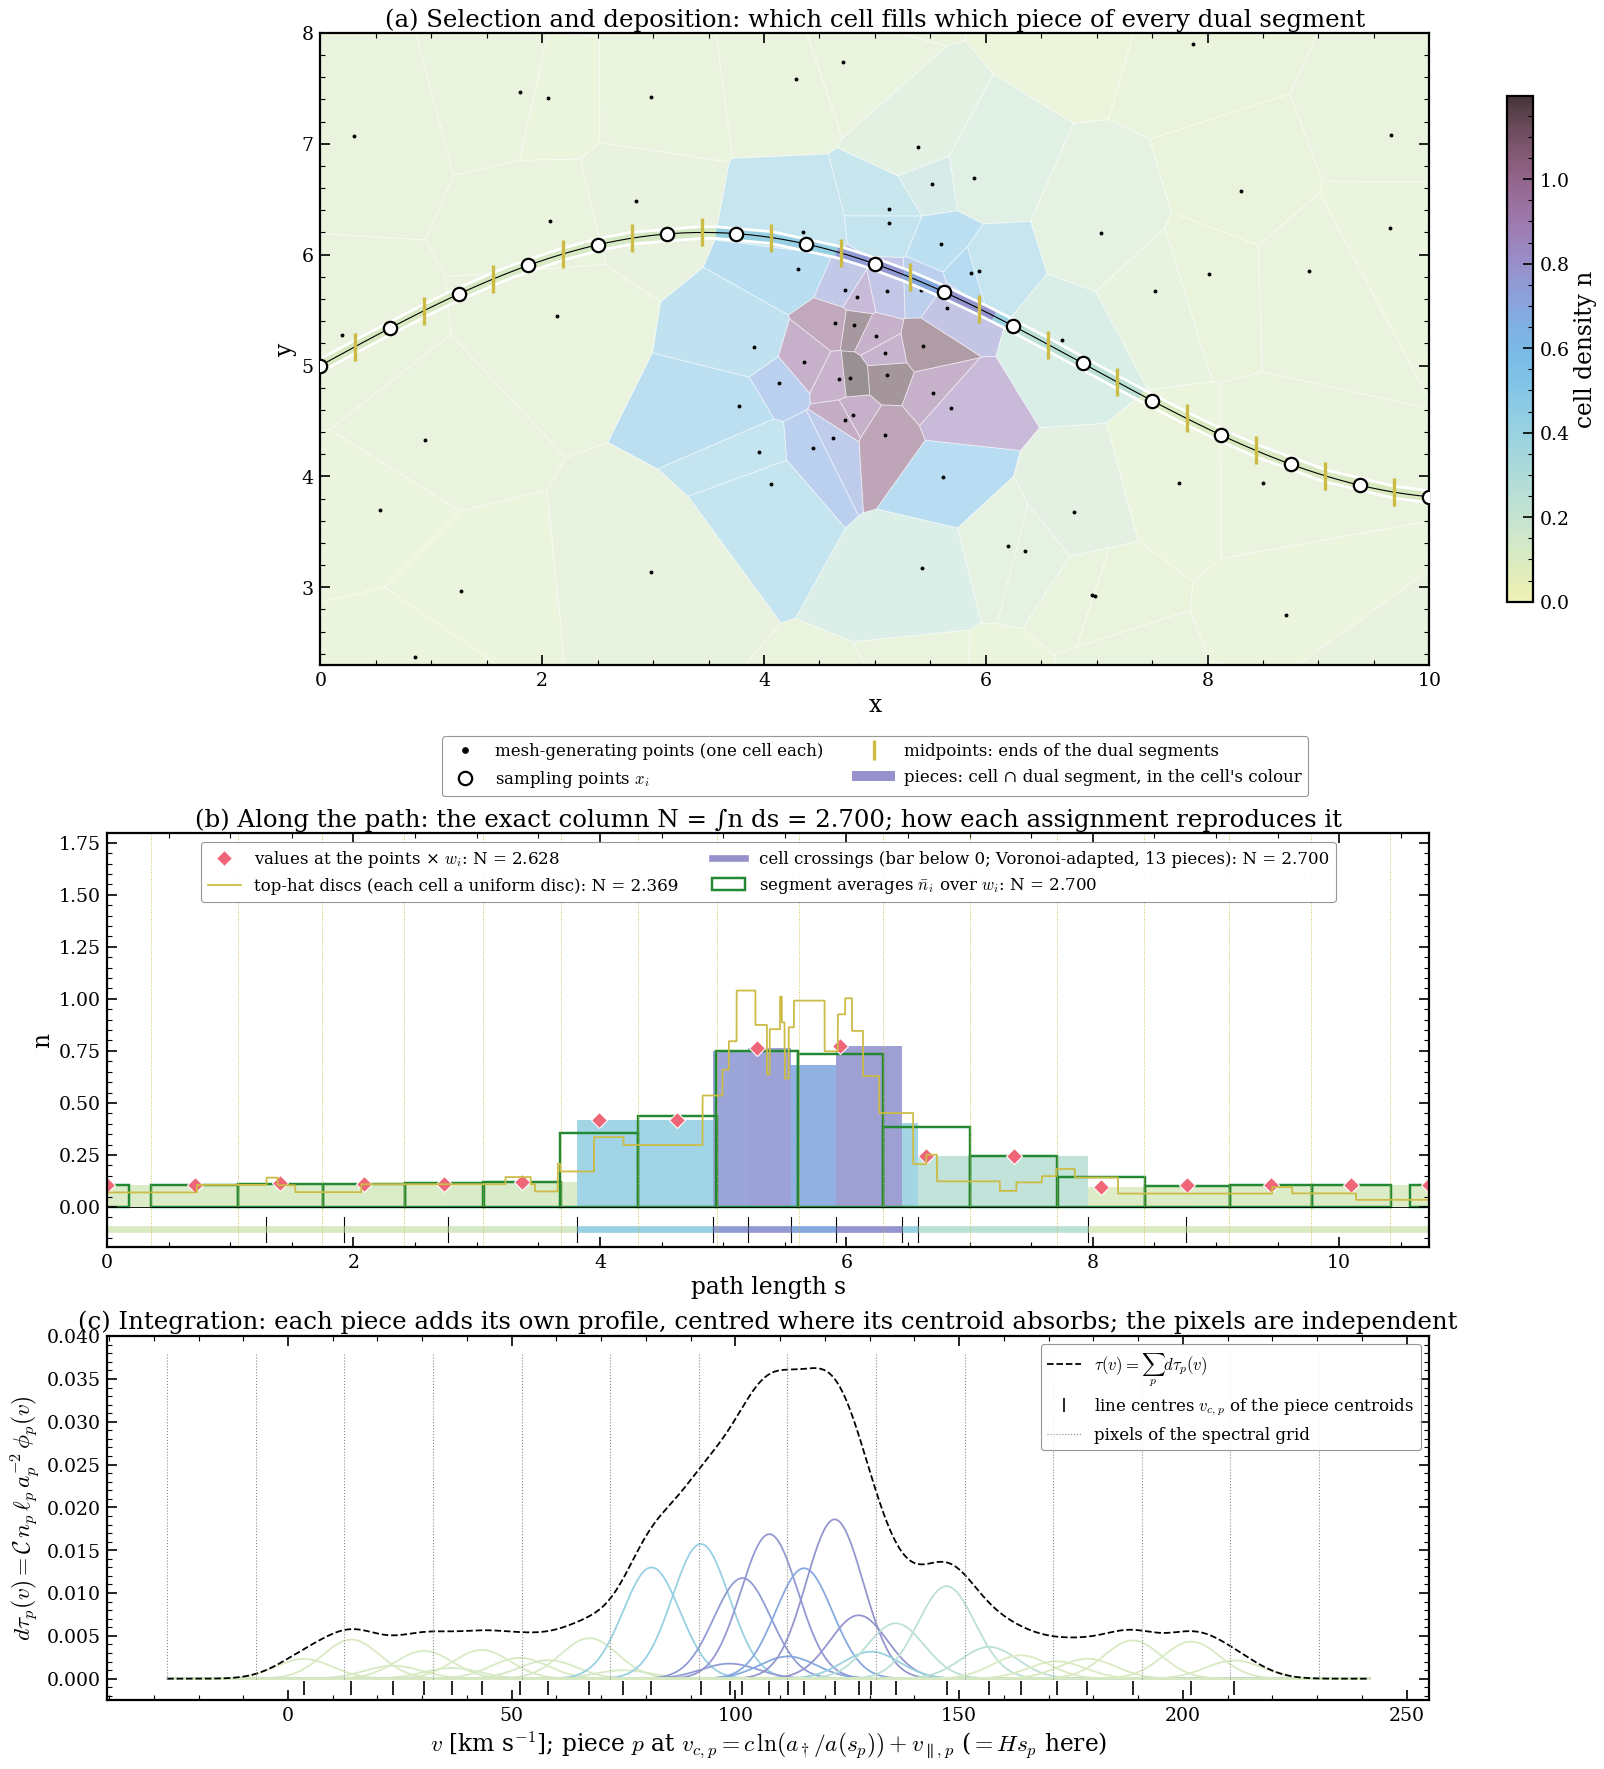

column along the path: exact 2.7004 | cell crossings 2.7004 | segment averages x w_i 2.7004 (+2.2e-16) | point values x w_i 2.6284 (-2.7%) | top-hat discs 2.3689 (-12.3%) | 29 pieces, 13 cell crossings


In [5]:
from skewerjax.utils.plotting import plot_deposition_story
fig, axs, col = plot_deposition_story()
plt.show()
print(f"column along the path: exact {col['exact']:.4f} | cell crossings {col['crossings']:.4f} | segment averages x w_i "
      f"{col['segments']:.4f} ({col['segments'] / col['exact'] - 1:+.1e}) | point values x w_i {col['points']:.4f} "
      f"({col['points'] / col['exact'] - 1:+.1%}) | top-hat discs {col['tophat']:.4f} ({col['tophat'] / col['exact'] - 1:+.1%}) | "
      f"{col['n_pieces']} pieces, {col['n_crossings']} cell crossings")

*Reading the figure.*

- **(a) Selection and deposition.** Each cell is filled with its density. The path is cut into pieces, one per
  (cell, dual segment) pair, and every piece is drawn in the colour of the cell that fills it. The sampling points
  know nothing about the cells, so a dual segment usually holds several pieces.
- **(b) How the gas is assigned to the path, and what it does to the column $N = \int n\, ds$.**
  - *Exact pieces* (SkewerJAX's default, `deposition="voronoi"`): every piece keeps its cell's density and its exact
    length, so $N$ is exact for any spacing of the points.
  - *Segment averages* $\bar n_i = \sum_{p\in i} n_p \ell_p / w_i$ (green bars): the length-weighted mean of the cells
    that dual segment $i$ crosses.
    - Since $\sum_i \bar n_i w_i = \sum_p n_p \ell_p$, they keep the exact column as well.
    - They are what a one-value-per-point integrator needs (`SimulationSkewers.point_values`, `fields`).
    - What they lose is where inside the segment the gas sits, and its velocity structure: all the pieces of a segment
      get one $T$ and one $v$.
  - *Point values* (red diamonds): whichever cell contains $x_i$. Their column depends on the spacing.
  - *Top hats* (`deposition="tophat"`, yellow): every cell becomes a uniform sphere (here a disc) of radius $V^{1/3}$
    that holds its atoms. The spheres overlap and leave gaps, so the density along the path is multi-valued and the
    column moves.
  - *Cell crossings* (`deposition="voronoi_crossings"`, the bar below zero): the pieces joined across the midpoints,
    one per crossing of a cell. The segmentation follows the cells, not the points, and the column is the same.
- **(c) Integration.**
  - Every piece adds its own profile $d\tau_p(v)$, centred at the line centre of its centroid (the ticks). In this
    toy, $a = 1$ and there are no peculiar velocities, so $v_{c,p} = H s_p$.
  - The sum of the profiles is $\tau(v)$.
  - The spectral grid (dotted) is a separate grid: every piece adds its profile whatever the pixels are.

**On the snapshot.** Any `SkewerBundle` can be used (`SimulationSkewers.from_bundle`, with its own $a(x)$). Here
there are three straight skewers along $x$, sampled every 0.25 km/s of Hubble flow:

1. the selection keeps the cells within reach of the paths;
2. the deposition finds the exact pieces of the Voronoi cells inside every dual segment;
3. the absorbers are those pieces, at their centroids.

The cell crossings are kept alongside the points (`SimulationSkewers.crossings()`). The column is the sum of
$n_p \ell_p$ over the pieces, whatever the spacing of the points.

In [6]:
cosmo = Cosmology(H0=100 * H.h * 1e6 * phys.Gyr_to_s / phys.Gpc_to_m, Omega_r_0=0.0, Omega_m_0=H.omega_m, Omega_k_0=0.0, Omega_lambda_0=H.omega_l)
L = H.box_cMpc
x = np.linspace(0.0, L, int(round(H.vmax_kms / 0.25)) + 1)
points = np.stack([np.stack([x, np.full_like(x, y), np.full_like(x, z)], -1) for y, z in [(10.0, 30.0), (25.0, 5.0), (40.0, 45.0)]])
bundle = SkewerBundle(spatial_points=jnp.asarray(points), a0=H.a, ICs_defined_at_index=0, ICs_at_emission_or_absorption="absorption", cosmologies=cosmo)
sk = SimulationSkewers.from_bundle(reader, bundle)                 # selection_backend="cpu" (default), "jztree" or "auto"
print(f"{len(sk.cells):,} cells selected in {sk.selection_s:.1f} s")
seg = sk.segments("voronoi"); A = sk.absorbers(HI)
cr = sk.crossings()
print(f"deposition: {int((seg.cell >= 0).sum()):,} pieces in {seg.cell.shape[0] * seg.cell.shape[1]:,} dual segments "
      f"(up to {seg.cell.shape[-1]} per segment); {int(cr.n_crossings.sum()):,} cell crossings (max gap {cr.diagnostics['max_gap']:.1e} cMpc)")
print(f"absorbers of skewer 0: {int((A.n[0] > 0).sum()):,} pieces; column {sk.column_per_pixel(HI)[0].sum():.3e} cm^-2 "
      f"= sum of n_p l_p (physical) {np.sum(A.n[0] * A.length[0]) * 3.085678e24 * H.a:.3e} cm^-2")

14,623 cells selected in 4.8 s
deposition: 48,562 pieces in 47,541 dual segments (up to 3 per segment); 1,024 cell crossings (max gap 1.4e-14 cMpc)
absorbers of skewer 0: 16,144 pieces; column 1.976e+16 cm^-2 = sum of n_p l_p (physical) 1.976e+16 cm^-2


**Options.**

- `ExtractionOptions`:
  - `deposition`: `"voronoi"` (default), `"tophat"`, `"points"` or `"voronoi_crossings"`;
  - `mass_unit`: `"amu"` or `"proton"`;
  - `T_constants` and `b_constants`: the physical constants of $T$ and $b$;
  - `x_HI_model`: `"stored_sf"` (default), `"stored"`, `"rahmati_all"`, ...;
  - `cloudy_density` and `cloudy_interpolation`: the density coordinate of the CLOUDY table, and `"linear"` or
    `"cubic"` interpolation.
- `IntegrationOptions`:
  - `frame`: `"exact"` (default) or `"snapshot"`;
  - `normalisation`;
  - `detuning`: `"exact"` (default) or `"linear"`;
  - `periodic`.

The non-default values reproduce the conventions of other codes; notebook 08 compares them. Checks:
`scripts/validation/check_tng_fields.py`, `check_tng_optical_depth.py`.